# Simulation timing estimations

This notebook reads the logs created in simulation test runs to perform regressions on the timings to estimate the time required for a complete run 

In [1]:
import pandas as pd
import numpy as np
import h5py as h5

import datetime as datetime
import matplotlib as mpl
import matplotlib.pyplot as plt


In [3]:
run_results = pd.read_hdf('../sim_data/mac_test/results_20230415_1307.h5')
run_results.set_index("int_length", inplace=True)

In [4]:
run_results.head()

,sim_number,clock_time
int_length,,
1000000.0,00003,107.458735
2500000.0,00003,273.403574
5000000.0,00003,541.987236
7500000.0,00003,817.452628
10000000.0,00003,1087.797607


sim_number
00003    Axes(0.125,0.11;0.775x0.77)
00004    Axes(0.125,0.11;0.775x0.77)
00005    Axes(0.125,0.11;0.775x0.77)
Name: clock_time, dtype: object

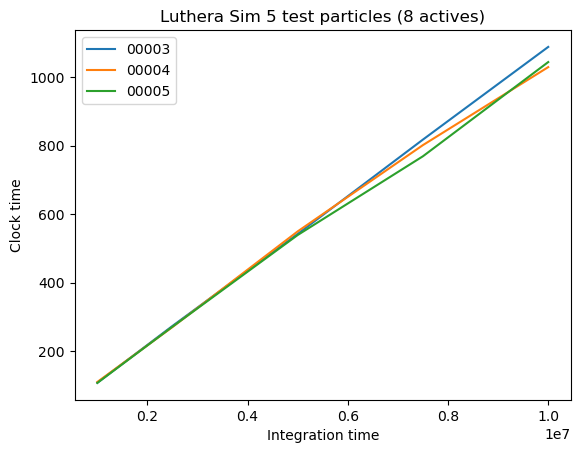

In [6]:
run_results.groupby("sim_number")["clock_time"].plot(legend=True, xlabel="Integration time", ylabel="Clock time", 
                                                     title="Luthera Sim 5 test particles (8 actives)")


In [7]:
avg_clock_time = run_results.groupby("int_length")["clock_time"].mean()

int_time = [float(int_time) for int_time in avg_clock_time.index]

lin_fit = np.polyfit(int_time, avg_clock_time,1)
reg_fun = np.poly1d(lin_fit)
print(reg_fun)

 
0.0001049 x + 9.072


In [8]:
print(reg_fun(int_time))
print(avg_clock_time)

print(f'Time to run 1.e6 {datetime.timedelta(seconds=reg_fun(1.e6))}')
print(f'Time to run 1.e7 {datetime.timedelta(seconds=reg_fun(1.e7))}')
print(f'Time to run 1.e8 {datetime.timedelta(seconds=reg_fun(1.e8))}')
print(f'Time to run 1.e9 {datetime.timedelta(seconds=reg_fun(1.e9))}')

print(f'Time to run 2.25e9 {datetime.timedelta(seconds=reg_fun(2.25e9))}')
print(f'Time to run 4.5e9 {datetime.timedelta(seconds=reg_fun(4.5e9))}')

[ 113.96121677  271.29448654  533.51660283  795.73871911 1057.96083539]
int_length
1000000.0      108.155760
2500000.0      271.621068
5000000.0      543.420321
7500000.0      795.851184
10000000.0    1053.423528
Name: clock_time, dtype: float64
Time to run 1.e6 0:01:53.961217
Time to run 1.e7 0:17:37.960835
Time to run 1.e8 2:54:57.957022
Time to run 1.e9 1 day, 5:08:17.918884
Time to run 2.25e9 2 days, 17:33:28.977025
Time to run 4.5e9 5 days, 11:06:48.881681


In [41]:
output = """+m_pm6_3 00000 1.0e+06
+m_pm6_3 00001 1.0e+06
+m_pm6_3 00002 1.0e+06
-m_pm6_3 00001 1.0e+06 stop_index:-1 Duration:0:00:42.591086
+m_pm6_3 00001 2.5e+06
-m_pm6_3 00000 1.0e+06 stop_index:-1 Duration:0:00:42.647985
+m_pm6_3 00000 2.5e+06
-m_pm6_3 00002 1.0e+06 stop_index:-1 Duration:0:00:42.691406
+m_pm6_3 00002 2.5e+06
-m_pm6_3 00000 2.5e+06 stop_index:-1 Duration:0:01:48.707366
+m_pm6_3 00000 5.0e+06
-m_pm6_3 00001 2.5e+06 stop_index:-1 Duration:0:01:48.763432
+m_pm6_3 00001 5.0e+06
-m_pm6_3 00002 2.5e+06 stop_index:-1 Duration:0:01:49.799747
+m_pm6_3 00002 5.0e+06
-m_pm6_3 00000 5.0e+06 stop_index:-1 Duration:0:03:35.501996
+m_pm6_3 00000 7.5e+06
-m_pm6_3 00001 5.0e+06 stop_index:-1 Duration:0:03:35.863213
+m_pm6_3 00001 7.5e+06
-m_pm6_3 00002 5.0e+06 stop_index:-1 Duration:0:03:36.372568
+m_pm6_3 00002 7.5e+06
-m_pm6_3 00000 7.5e+06 stop_index:-1 Duration:0:05:22.118932
+m_pm6_3 00000 1.0e+07
-m_pm6_3 00001 7.5e+06 stop_index:-1 Duration:0:05:21.883276
+m_pm6_3 00001 1.0e+07
-m_pm6_3 00002 7.5e+06 stop_index:-1 Duration:0:05:21.996928
+m_pm6_3 00002 1.0e+07
-m_pm6_3 00000 1.0e+07 stop_index:-1 Duration:0:07:22.665943
+m_pm6_3 00003 1.0e+06
-m_pm6_3 00001 1.0e+07 stop_index:-1 Duration:0:07:24.024309
+m_pm6_3 00004 1.0e+06
-m_pm6_3 00002 1.0e+07 stop_index:-1 Duration:0:07:27.447586
+m_pm6_3 00005 1.0e+06
-m_pm6_3 00003 1.0e+06 stop_index:-1 Duration:0:00:45.974686
+m_pm6_3 00003 2.5e+06
-m_pm6_3 00004 1.0e+06 stop_index:-1 Duration:0:00:45.883757
+m_pm6_3 00004 2.5e+06
-m_pm6_3 00005 1.0e+06 stop_index:-1 Duration:0:00:45.865479
+m_pm6_3 00005 2.5e+06
-m_pm6_3 00003 2.5e+06 stop_index:-1 Duration:0:01:45.762642
+m_pm6_3 00003 5.0e+06
-m_pm6_3 00004 2.5e+06 stop_index:-1 Duration:0:01:45.853678
+m_pm6_3 00004 5.0e+06
-m_pm6_3 00005 2.5e+06 stop_index:-1 Duration:0:01:46.604578
+m_pm6_3 00005 5.0e+06
-m_pm6_3 00003 5.0e+06 stop_index:-1 Duration:0:03:40.345223
+m_pm6_3 00003 7.5e+06
-m_pm6_3 00004 5.0e+06 stop_index:-1 Duration:0:03:40.342800
+m_pm6_3 00004 7.5e+06
-m_pm6_3 00005 5.0e+06 stop_index:-1 Duration:0:03:41.510097
+m_pm6_3 00005 7.5e+06
-m_pm6_3 00003 7.5e+06 stop_index:-1 Duration:0:05:29.920761
+m_pm6_3 00003 1.0e+07
-m_pm6_3 00004 7.5e+06 stop_index:-1 Duration:0:05:29.711988
+m_pm6_3 00004 1.0e+07
-m_pm6_3 00005 7.5e+06 stop_index:-1 Duration:0:05:31.908426
+m_pm6_3 00005 1.0e+07
-m_pm6_3 00003 1.0e+07 stop_index:-1 Duration:0:07:05.884037
+mc_pm6_3 00000 1.0e+06
-m_pm6_3 00004 1.0e+07 stop_index:-1 Duration:0:07:06.519574
+mc_pm6_3 00001 1.0e+06
-m_pm6_3 00005 1.0e+07 stop_index:-1 Duration:0:07:06.043109
+mc_pm6_3 00002 1.0e+06
-mc_pm6_3 00000 1.0e+06 stop_index:-1 Duration:0:00:52.236537
+mc_pm6_3 00000 2.5e+06
-mc_pm6_3 00001 1.0e+06 stop_index:-1 Duration:0:00:52.338285
+mc_pm6_3 00001 2.5e+06
-mc_pm6_3 00002 1.0e+06 stop_index:-1 Duration:0:00:52.117582
+mc_pm6_3 00002 2.5e+06
-mc_pm6_3 00000 2.5e+06 stop_index:-1 Duration:0:02:10.007362
+mc_pm6_3 00000 5.0e+06
-mc_pm6_3 00001 2.5e+06 stop_index:-1 Duration:0:02:09.991749
+mc_pm6_3 00001 5.0e+06
-mc_pm6_3 00002 2.5e+06 stop_index:-1 Duration:0:02:10.248585
+mc_pm6_3 00002 5.0e+06
-mc_pm6_3 00000 5.0e+06 stop_index:-1 Duration:0:04:20.473307
+mc_pm6_3 00000 7.5e+06
-mc_pm6_3 00001 5.0e+06 stop_index:-1 Duration:0:04:21.190247
+mc_pm6_3 00001 7.5e+06
-mc_pm6_3 00002 5.0e+06 stop_index:-1 Duration:0:04:20.067854
+mc_pm6_3 00002 7.5e+06
-mc_pm6_3 00000 7.5e+06 stop_index:-1 Duration:0:06:19.373663
+mc_pm6_3 00000 1.0e+07
-mc_pm6_3 00001 7.5e+06 stop_index:-1 Duration:0:06:19.779248
+mc_pm6_3 00001 1.0e+07
-mc_pm6_3 00002 7.5e+06 stop_index:-1 Duration:0:06:19.387427
+mc_pm6_3 00002 1.0e+07
-mc_pm6_3 00000 1.0e+07 stop_index:-1 Duration:0:08:09.932521
+mc_pm6_3 00003 1.0e+06
-mc_pm6_3 00001 1.0e+07 stop_index:-1 Duration:0:08:10.536392
+mc_pm6_3 00004 1.0e+06
-mc_pm6_3 00002 1.0e+07 stop_index:-1 Duration:0:08:09.902106
+mc_pm6_3 00005 1.0e+06
-mc_pm6_3 00003 1.0e+06 stop_index:-1 Duration:0:00:49.670463
+mc_pm6_3 00003 2.5e+06
-mc_pm6_3 00004 1.0e+06 stop_index:-1 Duration:0:00:49.681173
+mc_pm6_3 00004 2.5e+06
-mc_pm6_3 00005 1.0e+06 stop_index:-1 Duration:0:00:49.840305
+mc_pm6_3 00005 2.5e+06
-mc_pm6_3 00003 2.5e+06 stop_index:-1 Duration:0:02:04.648545
+mc_pm6_3 00003 5.0e+06
-mc_pm6_3 00004 2.5e+06 stop_index:-1 Duration:0:02:05.255025
+mc_pm6_3 00004 5.0e+06
-mc_pm6_3 00005 2.5e+06 stop_index:-1 Duration:0:02:04.836810
+mc_pm6_3 00005 5.0e+06
-mc_pm6_3 00003 5.0e+06 stop_index:-1 Duration:0:04:09.219367
+mc_pm6_3 00003 7.5e+06
-mc_pm6_3 00004 5.0e+06 stop_index:-1 Duration:0:04:10.435596
+mc_pm6_3 00004 7.5e+06
-mc_pm6_3 00005 5.0e+06 stop_index:-1 Duration:0:04:10.157329
+mc_pm6_3 00005 7.5e+06
-mc_pm6_3 00003 7.5e+06 stop_index:-1 Duration:0:06:13.172713
+mc_pm6_3 00003 1.0e+07
-mc_pm6_3 00004 7.5e+06 stop_index:-1 Duration:0:06:13.418599
+mc_pm6_3 00004 1.0e+07
-mc_pm6_3 00005 7.5e+06 stop_index:-1 Duration:0:06:13.806069
+mc_pm6_3 00005 1.0e+07
-mc_pm6_3 00003 1.0e+07 stop_index:-1 Duration:0:08:09.798776
-mc_pm6_3 00004 1.0e+07 stop_index:-1 Duration:0:08:10.335188
-mc_pm6_3 00005 1.0e+07 stop_index:-1 Duration:0:08:10.448171
"""

out_lines = output.split('\n')

config_times = []
for line in out_lines:
    if len(line) < 1:
        continue 
    if line[0] == '-':
        fields = line.split(' ')
        config = fields[0][1:]
        sim_no = fields[1]
        int_time = float(fields[2])
        elapsed = pd.Timedelta(fields[4][fields[4].index(':')+1:]).total_seconds()
        config_times.append([config, sim_no, int_time, elapsed])
        

cnfg_time_cols = ['config', 'sim_no', 'int_time', 'elapsed_time']
cnfg_time_df = pd.DataFrame(config_times, columns=cnfg_time_cols)


<Axes: title={'center': 'Luthera Sim 5 test particles (8 actives)'}, xlabel='Integration time', ylabel='Clock time'>

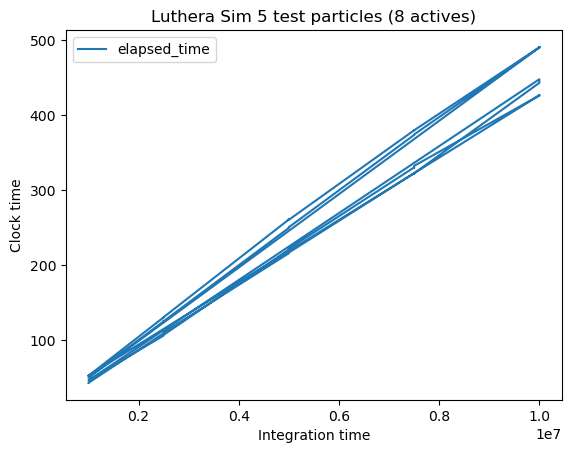

In [42]:
cnfg_time_df.plot(x='int_time', y='elapsed_time', legend=True, xlabel="Integration time", ylabel="Clock time", 
                                                     title="Luthera Sim 5 test particles (8 actives)")


In [45]:
avg_clock_time = cnfg_time_df[cnfg_time_df.config == 'mc_pm6_3'].groupby("int_time")["elapsed_time"].mean()
print(avg_clock_time)

int_time = [int_time for int_time in avg_clock_time.index]
print(int_time)

lin_fit = np.polyfit(int_time, avg_clock_time,1)
reg_fun = np.poly1d(lin_fit)
print(reg_fun)

int_time
1000000.0      50.980724
2500000.0     127.498013
5000000.0     255.257283
7500000.0     376.489620
10000000.0    490.158859
Name: elapsed_time, dtype: float64
[1000000.0, 2500000.0, 5000000.0, 7500000.0, 10000000.0]
 
4.895e-05 x + 5.514


In [52]:
print(reg_fun(int_time))
print(avg_clock_time)

print(f'Time to run 1.e6 {datetime.timedelta(seconds=reg_fun(1.e6))}')
print(f'Time to run 1.e7 {datetime.timedelta(seconds=reg_fun(1.e7))}')
print(f'Time to run 1.e8 {datetime.timedelta(seconds=reg_fun(1.e8))}')
print(f'Time to run 1.e9 {datetime.timedelta(seconds=reg_fun(1.e9))} {reg_fun(1.e9)}')

print(f'Time to run 2.25e9 {datetime.timedelta(seconds=reg_fun(2.25e9))}')
print(f'Time to run 4.5e9 {datetime.timedelta(seconds=reg_fun(4.5e9))} {reg_fun(4.5e9)}')

[ 54.46810488 127.89981735 250.2860048  372.67219225 495.05837971]
int_time
1000000.0      50.980724
2500000.0     127.498013
5000000.0     255.257283
7500000.0     376.489620
10000000.0    490.158859
Name: elapsed_time, dtype: float64
Time to run 1.e6 0:00:54.468105
Time to run 1.e7 0:08:15.058380
Time to run 1.e8 1:21:40.961128
Time to run 1.e9 13:35:59.988610 48959.98861020264
Time to run 2.25e9 1 day, 6:35:53.082336
Time to run 4.5e9 2 days, 13:11:40.651041 220300.65104125338


In [54]:
print(f'Time to run 4.5e9 * 19050 over 200 cores {datetime.timedelta(seconds=(reg_fun(1.0e9)*19000)/200)}')

Time to run 4.5e9 * 19050 over 200 cores 53 days, 19:59:58.917969
